# Loan Approval Classification: Traditional ML + Neural Network

**Pipeline:** Load data → Validate & clean → EDA → Preprocess → Baseline ML models → ANN → Hyperparameter tuning → Evaluate → Save model → Deploy (FastAPI / Streamlit)

**Use case:** Option E, Loan Approval Classification (hackathon brief).
**Target:** `loan_status` (1 = approved, 0 = not approved).
**Data:** `loan_data__1_.csv` (45,000 applicants, 13 features).

## 1. Setup

In [1]:
import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")

DATA_PATH = "loan_data__1_.csv"      # change this if your file is elsewhere
TARGET = "loan_status"
os.makedirs("artifacts", exist_ok=True)
print("TensorFlow", tf.__version__)

I0000 00:00:1795246169.142428    5901 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795246169.296368    5901 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795246170.815647    5901 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 2. Load & Validate Data

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (45000, 14)


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [3]:
print("Missing values per column:\n", df_raw.isna().sum().sum(), "total")
print("Duplicate rows:", df_raw.duplicated().sum())
print()
df_raw.info()

Missing values per column:
 0 total
Duplicate rows: 0

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  i

In [4]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,45000.0,27.764178,6.045108,20.00,24.00,26.00,30.00,144.00
person_income,45000.0,80319.053222,80422.498632,8000.00,47204.00,67048.00,95789.25,7200766.00
person_emp_exp,45000.0,5.410333,6.063532,0.00,1.00,4.00,8.00,125.00
loan_amnt,45000.0,9583.157556,6314.886691,500.00,5000.00,8000.00,12237.25,35000.00
loan_int_rate,45000.0,11.006606,2.978808,5.42,8.59,11.01,12.99,20.00
loan_percent_income,45000.0,0.139725,0.087212,0.00,0.07,0.12,0.19,0.66
cb_person_cred_hist_length,45000.0,5.867489,3.879702,2.00,3.00,4.00,8.00,30.00
credit_score,45000.0,632.608756,50.435865,390.00,601.00,640.00,670.00,850.00
loan_status,45000.0,0.222222,0.415744,0.00,0.00,0.00,0.00,1.00


loan_status
0    35000
1    10000
Name: count, dtype: int64
Approved rate: 22.2%


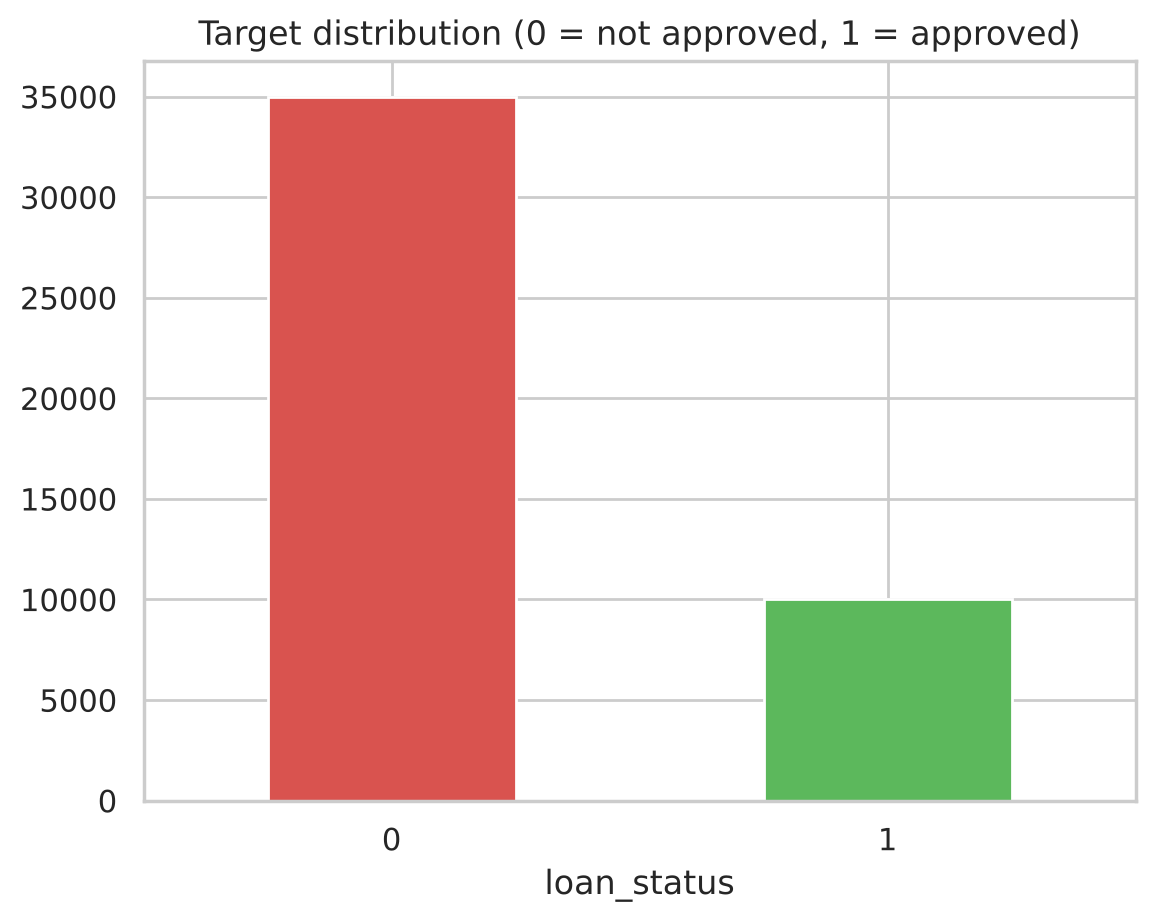

In [5]:
# Class imbalance check
counts = df_raw[TARGET].value_counts()
print(counts)
print(f"Approved rate: {df_raw[TARGET].mean():.1%}")
counts.plot(kind="bar", color=["#d9534f", "#5cb85c"], rot=0, title="Target distribution (0 = not approved, 1 = approved)")
plt.show()

**Observations**
- No missing values and no duplicates.
- Mild class imbalance (~78% / 22%), so I use class weights instead of discarding data.
- `person_age` max is 144 and `person_emp_exp` max is 125, which are impossible values (data-entry errors).
- `person_income` max is about 7.2M against a median of about 67K, a heavy right skew.

## 3. Data Cleaning

In [6]:
df = df_raw.copy()
n0 = len(df)

# 3.1 Standardise text columns
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].astype(str).str.strip()
df["person_gender"] = df["person_gender"].str.lower()
df["previous_loan_defaults_on_file"] = df["previous_loan_defaults_on_file"].str.capitalize()

# 3.2 Remove duplicates
df = df.drop_duplicates()

# 3.3 Remove impossible values
bad_age = (df["person_age"] < 18) | (df["person_age"] > 100)
bad_exp = df["person_emp_exp"] > (df["person_age"] - 14)     # cannot have worked before age 14
print("Rows with impossible age:", bad_age.sum())
print("Rows with impossible experience:", bad_exp.sum())
df = df[~(bad_age | bad_exp)]

# 3.4 Sanity checks on other numeric columns
df = df[(df["person_income"] > 0) & (df["loan_amnt"] > 0)]
df = df[df["credit_score"].between(300, 850)]

# 3.5 Fix dtypes
df["person_age"] = df["person_age"].astype(int)
df["cb_person_cred_hist_length"] = df["cb_person_cred_hist_length"].astype(int)
df = df.reset_index(drop=True)

print(f"\nRows: {n0} -> {len(df)}  (removed {n0 - len(df)})")
df.to_csv("artifacts/loan_data_cleaned.csv", index=False)
print("Saved artifacts/loan_data_cleaned.csv")

Rows with impossible age: 7
Rows with impossible experience: 0

Rows: 45000 -> 44993  (removed 7)


Saved artifacts/loan_data_cleaned.csv


## 4. Exploratory Data Analysis

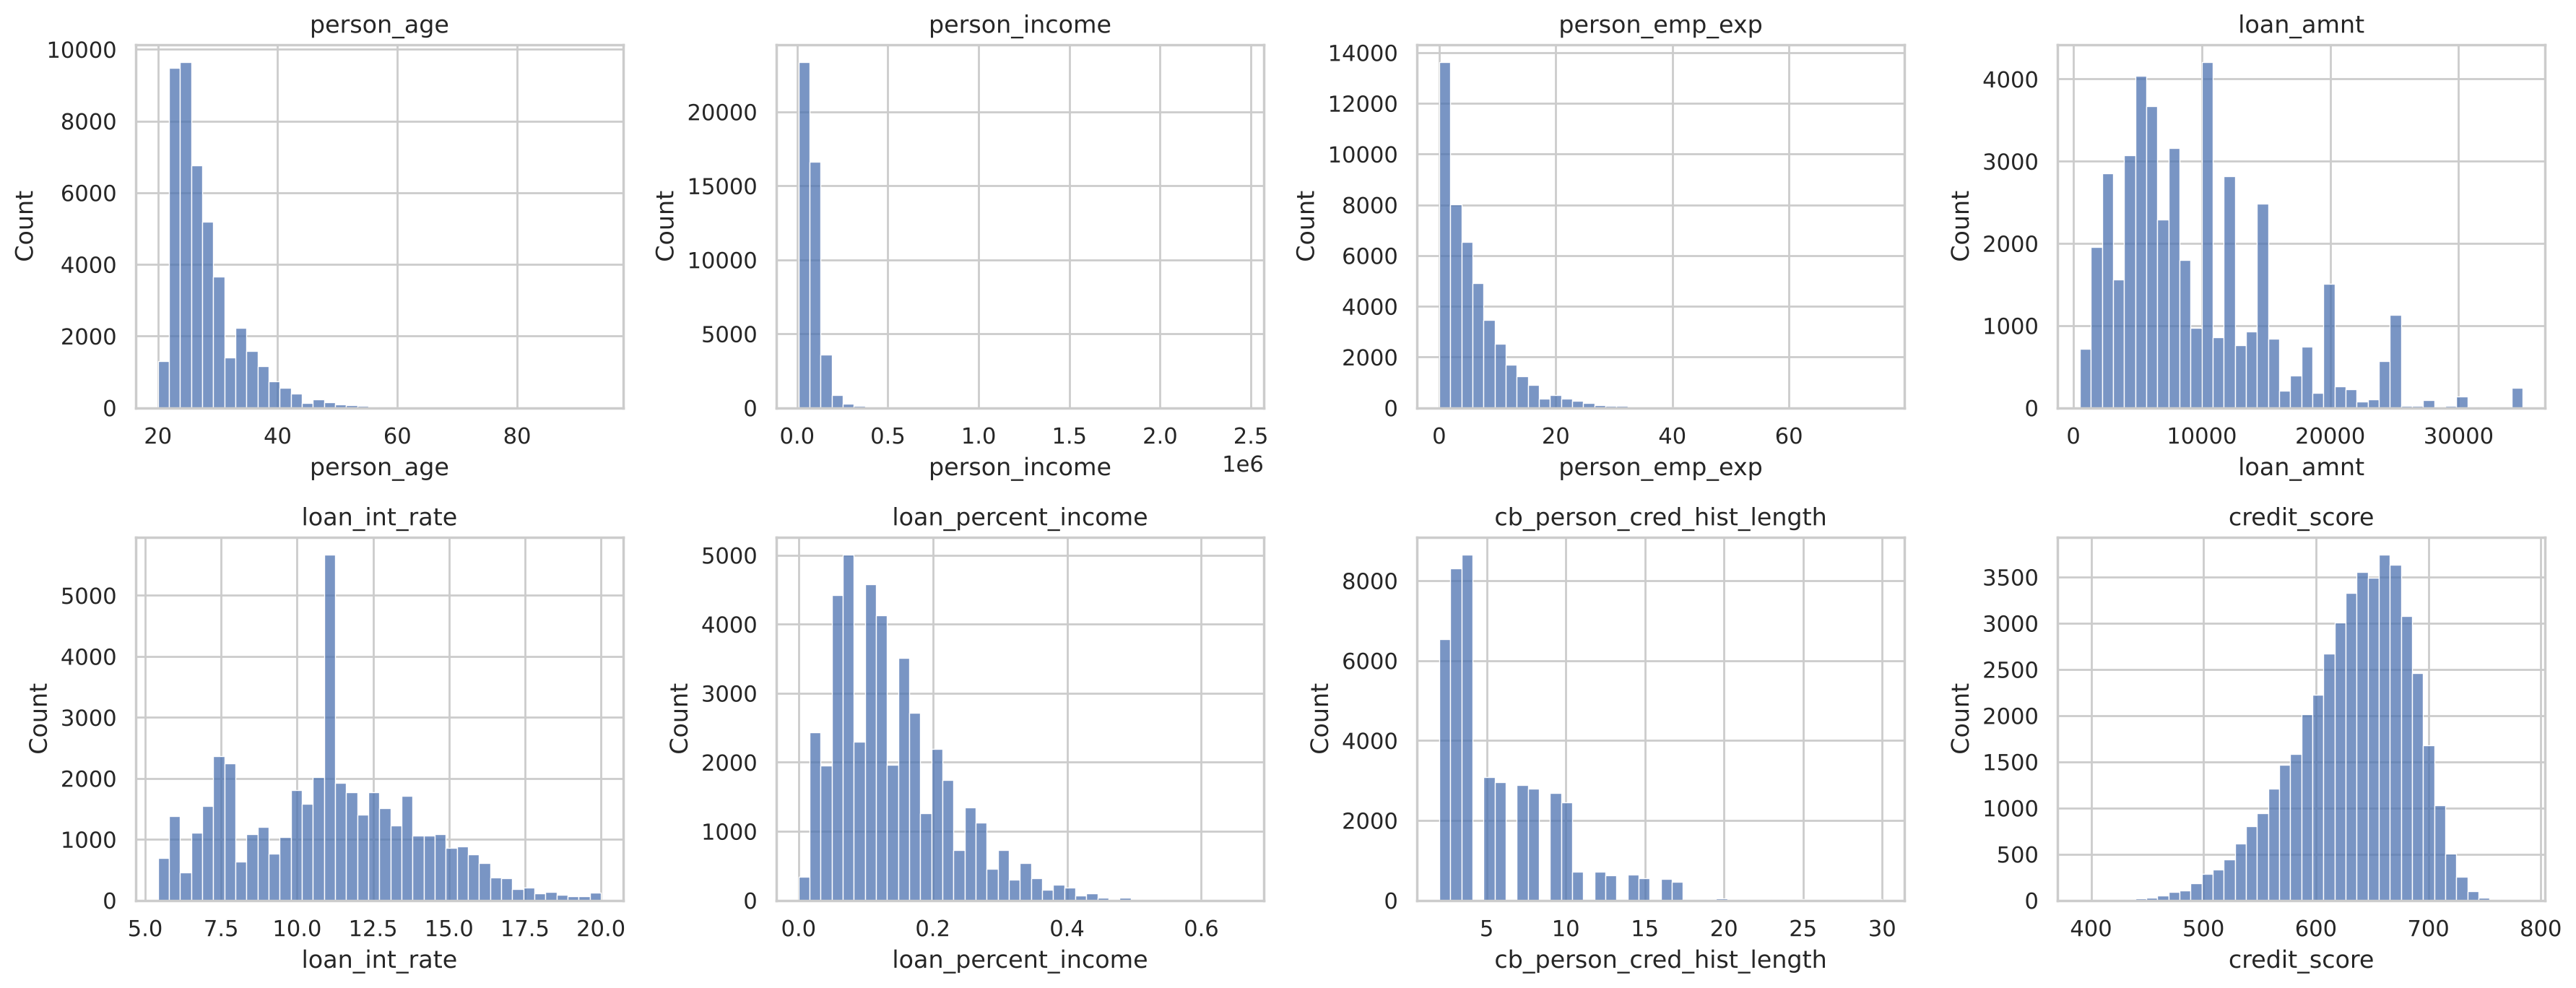

In [7]:
num_cols = ["person_age", "person_income", "person_emp_exp", "loan_amnt", "loan_int_rate",
            "loan_percent_income", "cb_person_cred_hist_length", "credit_score"]
cat_cols = ["person_gender", "person_education", "person_home_ownership",
            "loan_intent", "previous_loan_defaults_on_file"]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=40, ax=ax, color="#4c72b0")
    ax.set_title(c)
plt.tight_layout(); plt.show()

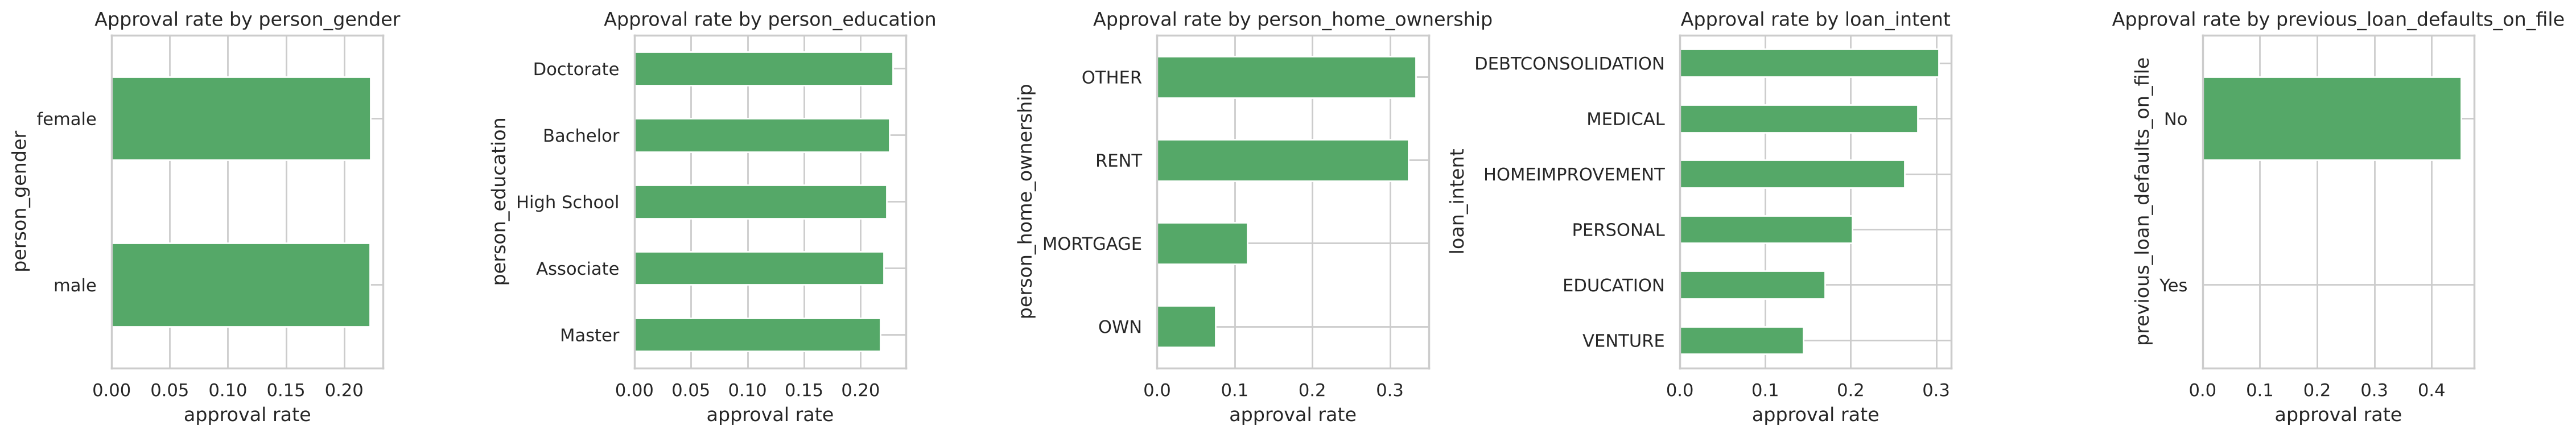

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, c in zip(axes, cat_cols):
    rate = df.groupby(c)[TARGET].mean().sort_values()
    rate.plot(kind="barh", ax=ax, color="#55a868")
    ax.set_title(f"Approval rate by {c}"); ax.set_xlabel("approval rate")
plt.tight_layout(); plt.show()

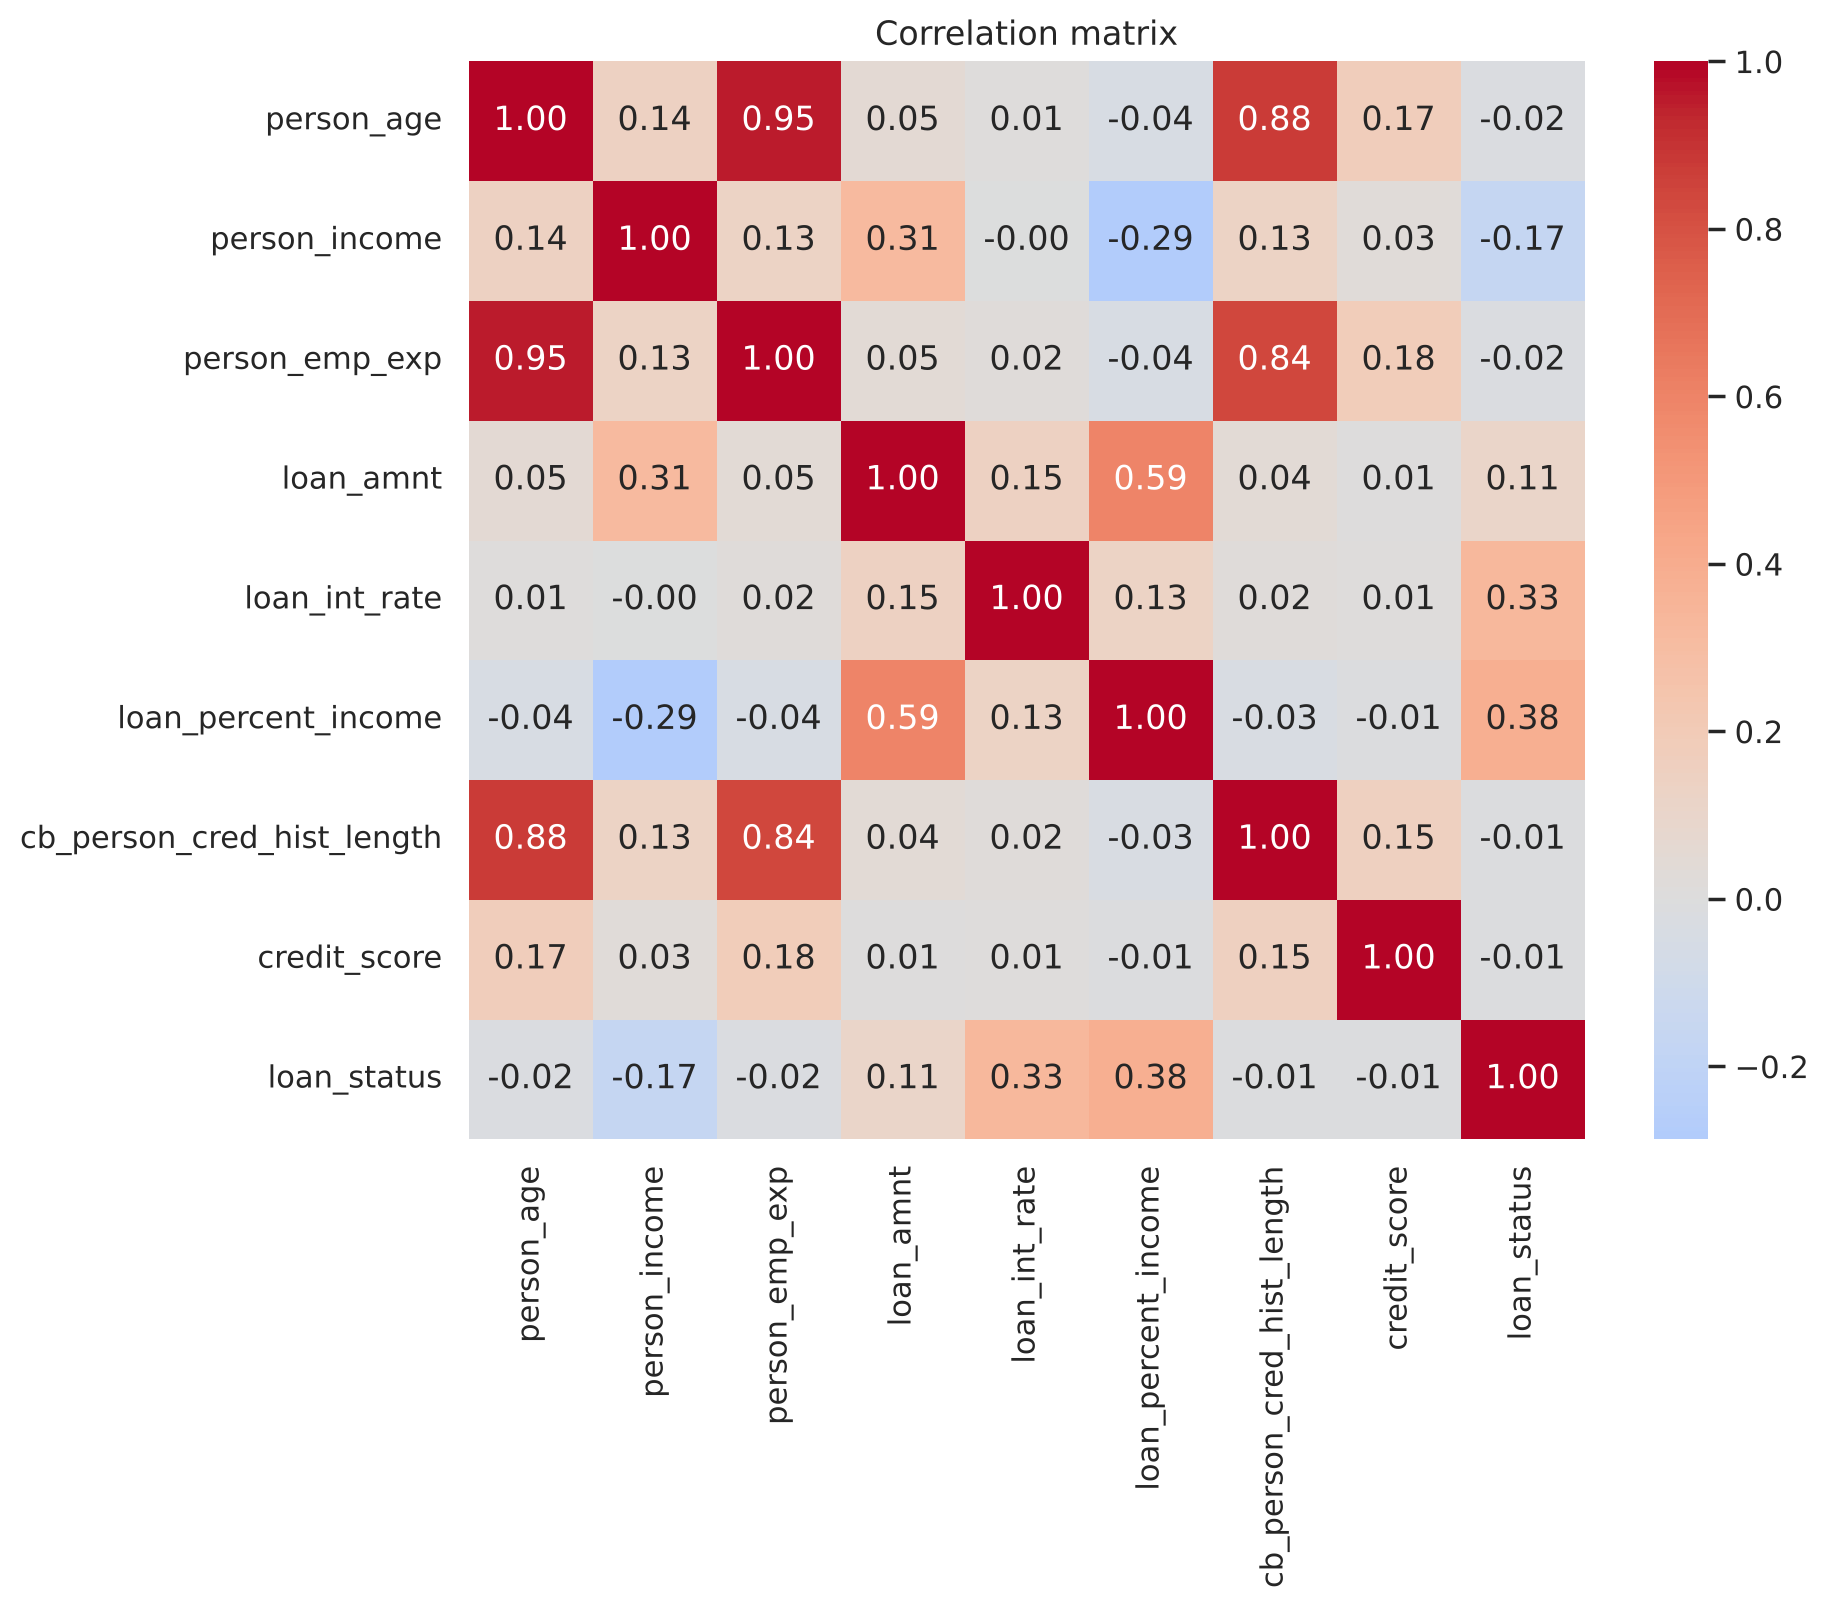

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

**Observations**
- `previous_loan_defaults_on_file = Yes` always leads to rejection (approval rate 0%). This is a strong business rule that every model will learn.
- Higher `loan_percent_income` and `loan_int_rate` go with lower approval; higher `credit_score` goes with higher approval.

## 5. Train / Validation / Test Split and Preprocessing

In [10]:
X = df.drop(columns=[TARGET])
y = df[TARGET].values

# 70% train / 15% validation / 15% test, stratified to keep the class ratio
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print("Train:", X_train.shape, " Val:", X_val.shape, " Test:", X_test.shape)
print("Approved rate  train/val/test:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

Train: (31495, 13)  Val: (6749, 13)  Test: (6749, 13)
Approved rate  train/val/test: 0.222 0.222 0.222


In [11]:
# Income is heavily skewed, so apply log1p before scaling
skewed_cols = ["person_income"]
scale_cols  = [c for c in num_cols if c not in skewed_cols]

preprocessor = ColumnTransformer([
    ("income", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                         ("scale", StandardScaler())]), skewed_cols),
    ("num", StandardScaler(), scale_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False), cat_cols),
])

# Fit on TRAIN only (no leakage), then transform all three sets
Xtr = preprocessor.fit_transform(X_train)
Xva = preprocessor.transform(X_val)
Xte = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print("Feature matrix:", Xtr.shape)
joblib.dump(preprocessor, "artifacts/preprocessor.joblib")

Feature matrix: (31495, 25)


['artifacts/preprocessor.joblib']

## 6. Evaluation Helper
One function so every model is scored the same way (accuracy, precision, recall, F1, AUC-ROC).

In [12]:
def evaluate(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "accuracy":  round(accuracy_score(y_true, y_pred), 4),
        "precision": round(precision_score(y_true, y_pred), 4),
        "recall":    round(recall_score(y_true, y_pred), 4),
        "f1_score":  round(f1_score(y_true, y_pred), 4),
        "roc_auc":   round(roc_auc_score(y_true, y_prob), 4),
    }

## 7. Traditional ML Baselines

In [13]:
lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
lr.fit(Xtr, y_train)

rf = RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_leaf=2,
                            class_weight="balanced", n_jobs=-1, random_state=SEED)
rf.fit(Xtr, y_train)

results_val = {
    "Logistic Regression": evaluate(y_val, lr.predict_proba(Xva)[:, 1]),
    "Random Forest":       evaluate(y_val, rf.predict_proba(Xva)[:, 1]),
}
pd.DataFrame(results_val).T

,accuracy,precision,recall,f1_score,roc_auc
Logistic Regression,0.8529,0.6136,0.9127,0.7339,0.9520
Random Forest,0.9167,0.7839,0.8633,0.8217,0.9729


## 8. Artificial Neural Network (ANN)
- **Architecture:** Input → Dense layers (He/Glorot init) → Dropout → Sigmoid output
- **Loss:** binary cross-entropy, **Optimizer:** Adam
- **Regularisation:** Dropout + early stopping; **imbalance:** class weights

In [14]:
classes = np.unique(y_train)
cw = compute_class_weight("balanced", classes=classes, y=y_train)
class_weight = {int(c): float(w) for c, w in zip(classes, cw)}
print("Class weights:", class_weight)

def build_ann(input_dim, hidden=(128, 64), activation="relu", dropout=0.3, lr=1e-3):
    init = "he_normal" if activation in ("relu", "elu") else "glorot_uniform"   # He for ReLU family, Glorot for tanh
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for units in hidden:
        model.add(layers.Dense(units, activation=activation, kernel_initializer=init))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

def train_ann(model, epochs=100, batch_size=256, verbose=0):
    es = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=8,
                                       restore_best_weights=True)
    rlr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)
    return model.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=epochs,
                     batch_size=batch_size, class_weight=class_weight,
                     callbacks=[es, rlr], verbose=verbose)

ann_base = build_ann(Xtr.shape[1])
ann_base.summary()
hist_base = train_ann(ann_base)
print("Stopped after", len(hist_base.history["loss"]), "epochs")

Class weights: {0: 0.6428863033272096, 1: 2.2496428571428573}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,649 (45.50 KB)

 Trainable params: 11,649 (45.50 KB)

 Non-trainable params: 0 (0.00 B)

Stopped after 59 epochs


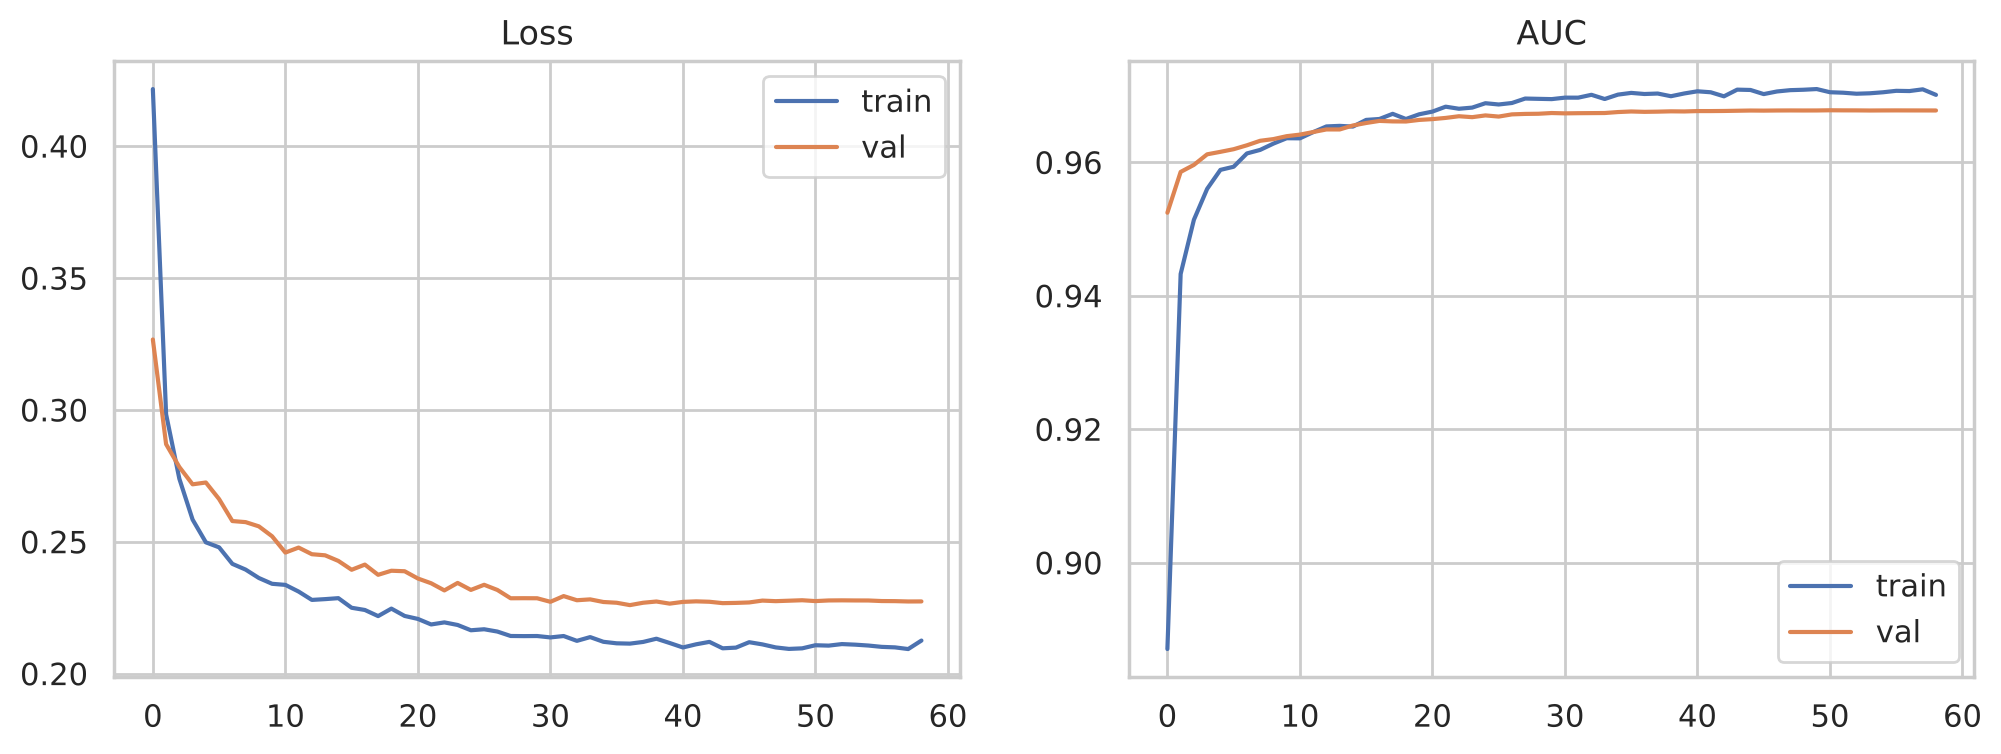

,accuracy,precision,recall,f1_score,roc_auc
Logistic Regression,0.8529,0.6136,0.9127,0.7339,0.9520
Random Forest,0.9167,0.7839,0.8633,0.8217,0.9729
ANN (baseline),0.8806,0.6709,0.9080,0.7717,0.9678


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_base.history["loss"], label="train"); ax[0].plot(hist_base.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist_base.history["auc"], label="train"); ax[1].plot(hist_base.history["val_auc"], label="val")
ax[1].set_title("AUC"); ax[1].legend()
plt.show()

results_val["ANN (baseline)"] = evaluate(y_val, ann_base.predict(Xva, verbose=0).ravel())
pd.DataFrame(results_val).T

## 9. Hyperparameter Tuning (Random Search)
Searching learning rate, number of layers/units, activation function and dropout rate. Models are ranked on **validation AUC**; the test set is not touched.

In [16]:
import time
rng = np.random.default_rng(SEED)

search_space = {
    "lr":         [1e-2, 3e-3, 1e-3, 5e-4],
    "hidden":     [(64, 32), (128, 64), (128, 64, 32), (256, 128, 64)],
    "activation": ["relu", "elu", "tanh"],
    "dropout":    [0.1, 0.2, 0.3, 0.4],
    "batch_size": [128, 256, 512],
}
N_TRIALS = 10
trials = []
for i in range(N_TRIALS):
    p = {k: v[rng.integers(len(v))] for k, v in search_space.items()}
    tf.keras.utils.set_random_seed(SEED + i)
    m = build_ann(Xtr.shape[1], hidden=p["hidden"], activation=p["activation"],
                  dropout=p["dropout"], lr=p["lr"])
    t0 = time.time()
    h = train_ann(m, epochs=60, batch_size=p["batch_size"])
    prob = m.predict(Xva, verbose=0).ravel()
    row = {**p, "hidden": str(p["hidden"]), "epochs_run": len(h.history["loss"]),
           **{f"val_{k}": v for k, v in evaluate(y_val, prob).items()}, "secs": round(time.time() - t0, 1)}
    trials.append((row, p))
    print(f"Trial {i+1:>2}/{N_TRIALS}: val_auc={row['val_roc_auc']}  val_f1={row['val_f1_score']}  {p}")

tuning_df = pd.DataFrame([r for r, _ in trials]).sort_values("val_roc_auc", ascending=False).reset_index(drop=True)
tuning_df.to_csv("artifacts/tuning_results.csv", index=False)
tuning_df

Trial  1/10: val_auc=0.9688  val_f1=0.7741  {'lr': 0.01, 'hidden': (256, 128, 64), 'activation': 'elu', 'dropout': 0.2, 'batch_size': 256}


Trial  2/10: val_auc=0.9663  val_f1=0.7747  {'lr': 0.0005, 'hidden': (64, 32), 'activation': 'tanh', 'dropout': 0.1, 'batch_size': 128}


Trial  3/10: val_auc=0.954  val_f1=0.7404  {'lr': 0.001, 'hidden': (256, 128, 64), 'activation': 'tanh', 'dropout': 0.4, 'batch_size': 512}


Trial  4/10: val_auc=0.966  val_f1=0.7569  {'lr': 0.0005, 'hidden': (128, 64, 32), 'activation': 'relu', 'dropout': 0.4, 'batch_size': 256}


Trial  5/10: val_auc=0.9668  val_f1=0.7697  {'lr': 0.001, 'hidden': (128, 64), 'activation': 'relu', 'dropout': 0.4, 'batch_size': 512}


Trial  6/10: val_auc=0.9637  val_f1=0.7605  {'lr': 0.001, 'hidden': (128, 64), 'activation': 'tanh', 'dropout': 0.3, 'batch_size': 256}


Trial  7/10: val_auc=0.9673  val_f1=0.7675  {'lr': 0.003, 'hidden': (64, 32), 'activation': 'relu', 'dropout': 0.3, 'batch_size': 512}


Trial  8/10: val_auc=0.969  val_f1=0.7816  {'lr': 0.01, 'hidden': (256, 128, 64), 'activation': 'tanh', 'dropout': 0.2, 'batch_size': 256}


Trial  9/10: val_auc=0.9693  val_f1=0.7884  {'lr': 0.01, 'hidden': (256, 128, 64), 'activation': 'tanh', 'dropout': 0.2, 'batch_size': 128}


Trial 10/10: val_auc=0.9535  val_f1=0.7403  {'lr': 0.0005, 'hidden': (128, 64), 'activation': 'tanh', 'dropout': 0.3, 'batch_size': 512}


,lr,hidden,activation,dropout,batch_size,epochs_run,val_accuracy,val_precision,val_recall,val_f1_score,val_roc_auc,secs
0,0.0100,"(256, 128, 64)",tanh,0.2,128,26,0.8927,0.7019,0.8993,0.7884,0.9693,33.6
1,0.0100,"(256, 128, 64)",tanh,0.2,256,49,0.8887,0.6931,0.8960,0.7816,0.9690,33.8
2,0.0100,"(256, 128, 64)",elu,0.2,256,36,0.8815,0.6714,0.9140,0.7741,0.9688,24.9
3,0.0030,"(64, 32)",relu,0.3,512,30,0.8772,0.6625,0.9120,0.7675,0.9673,10.2
4,0.0010,"(128, 64)",relu,0.4,512,52,0.8789,0.6668,0.9100,0.7697,0.9668,17.1
5,0.0005,"(64, 32)",tanh,0.1,128,60,0.8818,0.6719,0.9147,0.7747,0.9663,43.4
6,0.0005,"(128, 64, 32)",relu,0.4,256,60,0.8683,0.6416,0.9227,0.7569,0.9660,37.5
7,0.0010,"(128, 64)",tanh,0.3,256,50,0.8724,0.6525,0.9113,0.7605,0.9637,30.3
8,0.0010,"(256, 128, 64)",tanh,0.4,512,60,0.8583,0.6247,0.9087,0.7404,0.9540,38.5
9,0.0005,"(128, 64)",tanh,0.3,512,44,0.8578,0.6230,0.9120,0.7403,0.9535,14.8


In [17]:
best_row, best_params = max(trials, key=lambda t: t[0]["val_roc_auc"])
print("Best hyperparameters:", best_params)

# Retrain the best configuration from scratch for the final model
tf.keras.utils.set_random_seed(SEED)
ann = build_ann(Xtr.shape[1], hidden=best_params["hidden"], activation=best_params["activation"],
                dropout=best_params["dropout"], lr=best_params["lr"])
hist = train_ann(ann, epochs=100, batch_size=best_params["batch_size"])
print("Final ANN trained for", len(hist.history["loss"]), "epochs")
results_val["ANN (tuned)"] = evaluate(y_val, ann.predict(Xva, verbose=0).ravel())
pd.DataFrame(results_val).T

Best hyperparameters: {'lr': 0.01, 'hidden': (256, 128, 64), 'activation': 'tanh', 'dropout': 0.2, 'batch_size': 128}


Final ANN trained for 46 epochs


,accuracy,precision,recall,f1_score,roc_auc
Logistic Regression,0.8529,0.6136,0.9127,0.7339,0.9520
Random Forest,0.9167,0.7839,0.8633,0.8217,0.9729
ANN (baseline),0.8806,0.6709,0.9080,0.7717,0.9678
ANN (tuned),0.8840,0.6774,0.9127,0.7776,0.9687


## 10. Final Evaluation on the Held-Out Test Set

In [18]:
probs = {
    "Logistic Regression": lr.predict_proba(Xte)[:, 1],
    "Random Forest":       rf.predict_proba(Xte)[:, 1],
    "ANN (tuned)":         ann.predict(Xte, verbose=0).ravel(),
}
test_results = {name: evaluate(y_test, p) for name, p in probs.items()}
comparison = pd.DataFrame(test_results).T
comparison

,accuracy,precision,recall,f1_score,roc_auc
Logistic Regression,0.8598,0.6251,0.9227,0.7453,0.9544
Random Forest,0.9213,0.7960,0.8687,0.8307,0.9748
ANN (tuned),0.8794,0.6693,0.9040,0.7691,0.9685


In [19]:
# Example JSON output in the format requested by the brief
print(json.dumps(test_results["ANN (tuned)"], indent=2))

{
  "accuracy": 0.8794,
  "precision": 0.6693,
  "recall": 0.904,
  "f1_score": 0.7691,
  "roc_auc": 0.9685
}


In [20]:
print(classification_report(y_test, (probs["ANN (tuned)"] >= 0.5).astype(int),
                            target_names=["Not approved", "Approved"]))

              precision    recall  f1-score   support

Not approved       0.97      0.87      0.92      5249
    Approved       0.67      0.90      0.77      1500

    accuracy                           0.88      6749
   macro avg       0.82      0.89      0.84      6749
weighted avg       0.90      0.88      0.89      6749



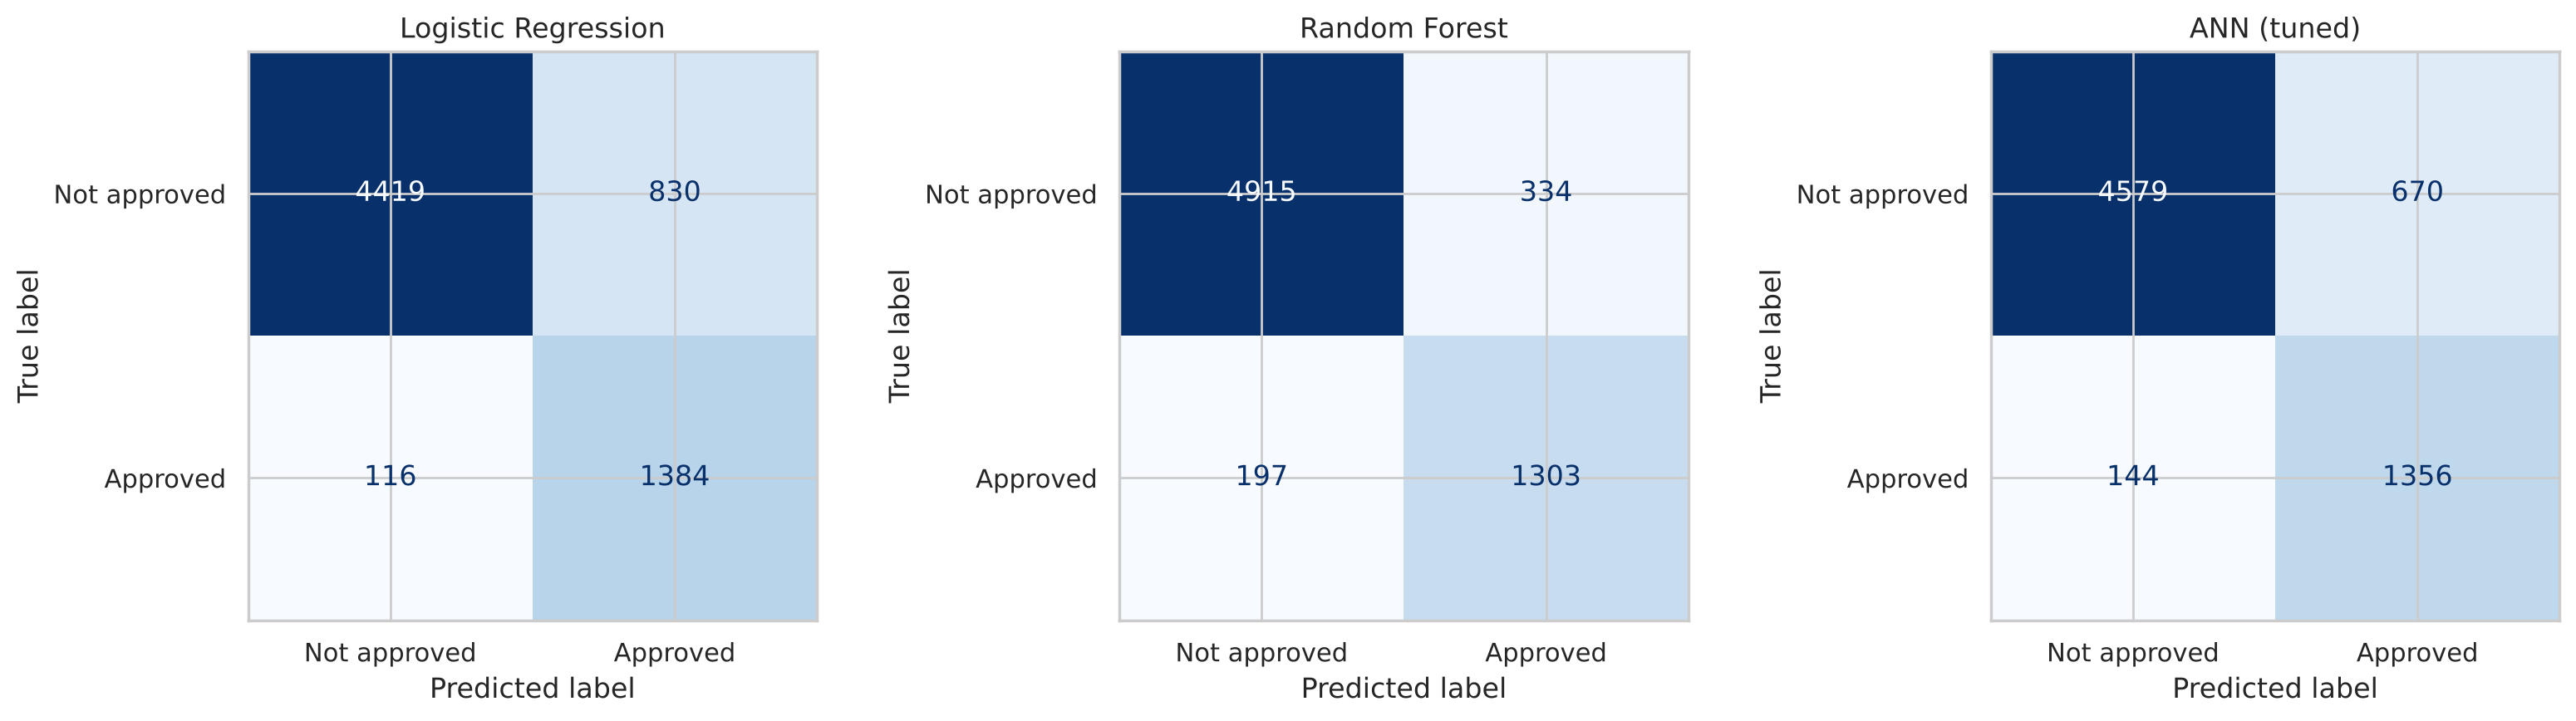

In [21]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, p) in zip(axes, probs.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Not approved", "Approved"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

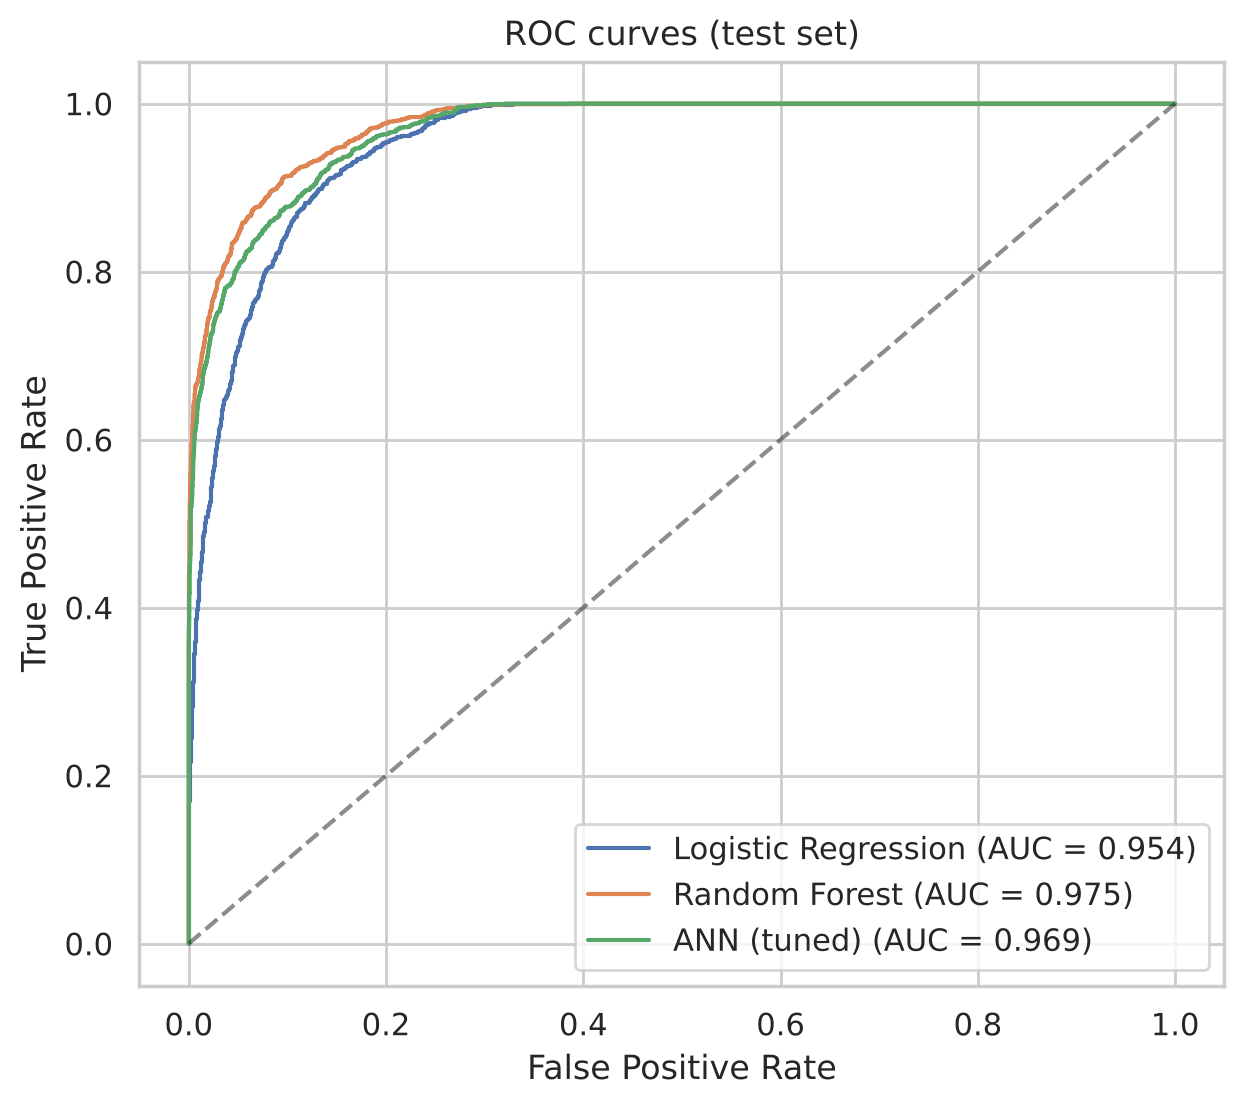

In [22]:
# ROC curves
plt.figure(figsize=(7, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC curves (test set)")
plt.legend(); plt.show()

## 11. Feature Importance

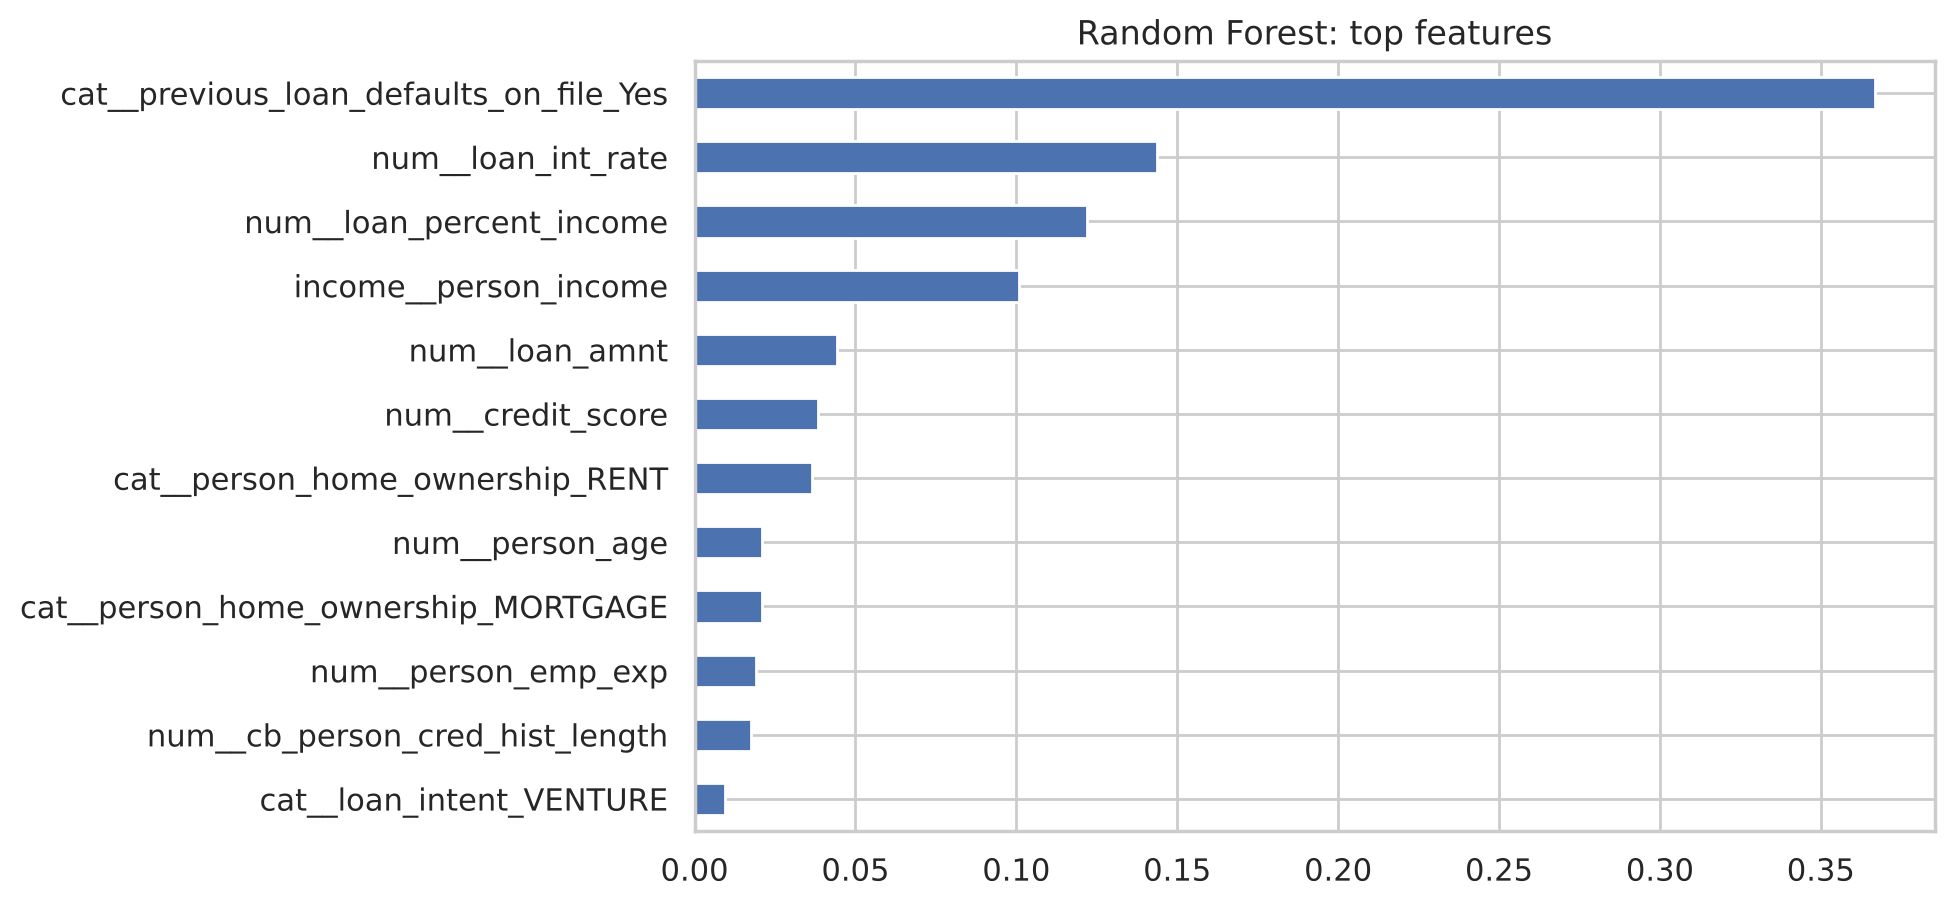

In [23]:
# (a) Random Forest built-in importance on the encoded features
rf_imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False).head(12)
rf_imp[::-1].plot(kind="barh", figsize=(8, 5), color="#4c72b0", title="Random Forest: top features")
plt.show()

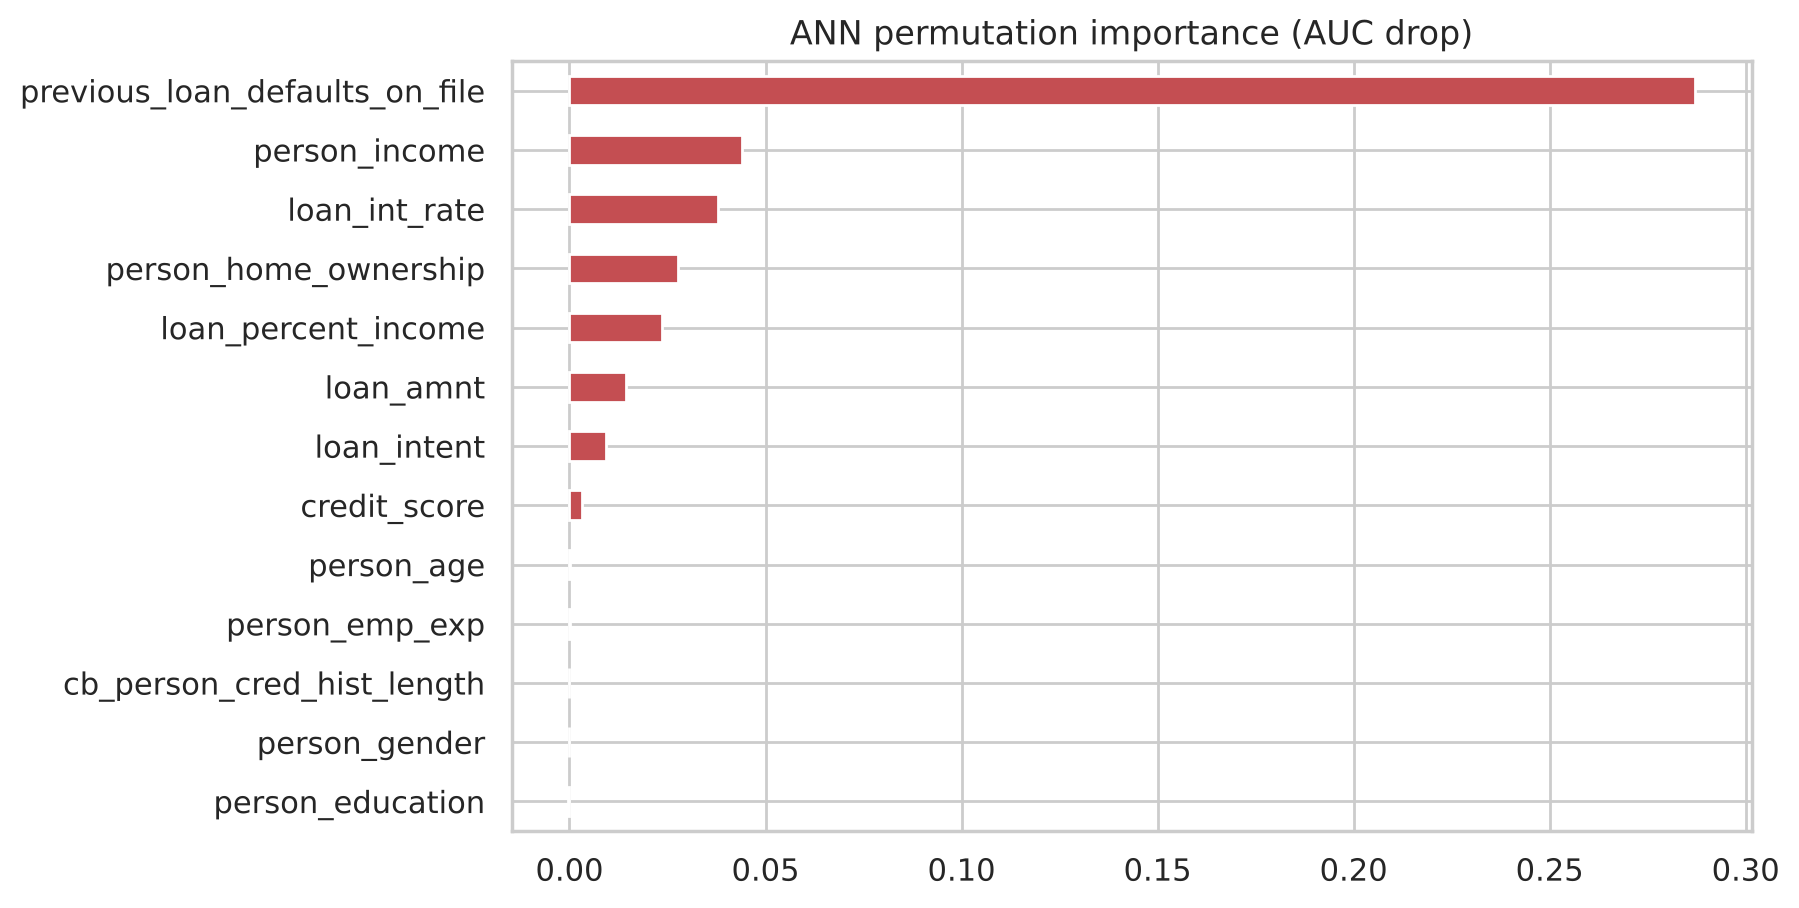

In [24]:
# (b) Permutation importance for the ANN on the ORIGINAL columns:
#     shuffle one column, see how much AUC drops
def ann_predict_raw(X_raw):
    return ann.predict(preprocessor.transform(X_raw), verbose=0).ravel()

base_auc = roc_auc_score(y_test, ann_predict_raw(X_test))
perm = {}
for col in X_test.columns:
    drops = []
    for r in range(3):
        Xp = X_test.copy()
        Xp[col] = Xp[col].sample(frac=1, random_state=SEED + r).values
        drops.append(base_auc - roc_auc_score(y_test, ann_predict_raw(Xp)))
    perm[col] = np.mean(drops)

perm_s = pd.Series(perm).sort_values()
perm_s.plot(kind="barh", figsize=(8, 5), color="#c44e52", title="ANN permutation importance (AUC drop)")
plt.show()

## 12. Save Model Artifacts

In [25]:
ann.save("artifacts/loan_ann.keras")      # recommended Keras format
ann.save("artifacts/loan_ann.h5")         # .h5 as requested in the brief
joblib.dump(rf, "artifacts/random_forest.joblib")
joblib.dump(lr, "artifacts/logistic_regression.joblib")

report = {"best_hyperparameters": {k: (list(v) if isinstance(v, tuple) else v) for k, v in best_params.items()},
          "test_metrics": test_results,
          "validation_metrics": results_val}
with open("artifacts/metrics.json", "w") as f:
    json.dump(report, f, indent=2)
print(os.listdir("artifacts"))

['random_forest.joblib', 'preprocessor.joblib', 'metrics.json', 'loan_data_cleaned.csv', 'loan_ann.keras', 'logistic_regression.joblib', 'loan_ann.h5', 'tuning_results.csv']


## 13. Deployment
Two options from the brief: a **FastAPI** REST endpoint and a **Streamlit** UI. Both load the saved preprocessor and ANN.

Run after this notebook finishes:
```
uvicorn api:app --reload          # API docs at http://127.0.0.1:8000/docs
streamlit run streamlit_app.py    # UI
```

In [26]:
%%writefile api.py
import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, Field
from tensorflow import keras

app = FastAPI(title="Loan Approval API")
preprocessor = joblib.load("artifacts/preprocessor.joblib")
model = keras.models.load_model("artifacts/loan_ann.keras")

class Applicant(BaseModel):
    person_age: int = Field(..., ge=18, le=100)
    person_gender: str = Field(..., examples=["female"])
    person_education: str = Field(..., examples=["Bachelor"])
    person_income: float = Field(..., gt=0)
    person_emp_exp: int = Field(..., ge=0)
    person_home_ownership: str = Field(..., examples=["RENT"])
    loan_amnt: float = Field(..., gt=0)
    loan_intent: str = Field(..., examples=["PERSONAL"])
    loan_int_rate: float = Field(..., gt=0)
    cb_person_cred_hist_length: int = Field(..., ge=0)
    credit_score: int = Field(..., ge=300, le=850)
    previous_loan_defaults_on_file: str = Field(..., examples=["No"])

@app.get("/")
def health():
    return {"status": "ok"}

@app.post("/predict")
def predict(a: Applicant):
    row = a.model_dump()
    row["loan_percent_income"] = round(row["loan_amnt"] / row["person_income"], 2)
    X = preprocessor.transform(pd.DataFrame([row]))
    prob = float(model.predict(X, verbose=0).ravel()[0])
    return {"approved": prob >= 0.5, "approval_probability": round(prob, 4)}

Writing api.py


In [27]:
%%writefile streamlit_app.py
import joblib
import pandas as pd
import streamlit as st
from tensorflow import keras

st.set_page_config(page_title="Loan Approval Predictor", page_icon="🏦")

@st.cache_resource
def load():
    return joblib.load("artifacts/preprocessor.joblib"), keras.models.load_model("artifacts/loan_ann.keras")

preprocessor, model = load()
st.title("🏦 Loan Approval Predictor")

c1, c2 = st.columns(2)
with c1:
    age = st.number_input("Age", 18, 100, 28)
    gender = st.selectbox("Gender", ["female", "male"])
    education = st.selectbox("Education", ["High School", "Associate", "Bachelor", "Master", "Doctorate"])
    income = st.number_input("Annual income", 1000, 5_000_000, 60000, step=1000)
    exp = st.number_input("Years of employment experience", 0, 60, 3)
    home = st.selectbox("Home ownership", ["RENT", "MORTGAGE", "OWN", "OTHER"])
with c2:
    amnt = st.number_input("Loan amount", 500, 35000, 8000, step=500)
    intent = st.selectbox("Loan purpose", ["EDUCATION", "MEDICAL", "VENTURE", "PERSONAL", "DEBTCONSOLIDATION", "HOMEIMPROVEMENT"])
    rate = st.slider("Interest rate (%)", 5.0, 20.0, 11.0, 0.1)
    hist = st.number_input("Credit history length (years)", 0, 40, 4)
    score = st.slider("Credit score", 300, 850, 640)
    default = st.selectbox("Previous loan default on file?", ["No", "Yes"])

if st.button("Predict"):
    row = {"person_age": age, "person_gender": gender, "person_education": education,
           "person_income": income, "person_emp_exp": exp, "person_home_ownership": home,
           "loan_amnt": amnt, "loan_intent": intent, "loan_int_rate": rate,
           "loan_percent_income": round(amnt / income, 2),
           "cb_person_cred_hist_length": hist, "credit_score": score,
           "previous_loan_defaults_on_file": default}
    prob = float(model.predict(preprocessor.transform(pd.DataFrame([row])), verbose=0).ravel()[0])
    if prob >= 0.5:
        st.success(f"Likely APPROVED (probability {prob:.1%})")
    else:
        st.error(f"Likely NOT approved (probability {prob:.1%})")
    st.progress(prob)

Writing streamlit_app.py


In [28]:
%%writefile requirements.txt
pandas
numpy
scikit-learn
tensorflow
joblib
matplotlib
seaborn
fastapi
uvicorn
streamlit

Writing requirements.txt


## 14. Summary
- Cleaned 45,000 records (removed impossible ages/experience), saved to `artifacts/loan_data_cleaned.csv`.
- Compared Logistic Regression and Random Forest against a tuned ANN on the same held-out test set.
- Handled class imbalance with class weights and overfitting with dropout and early stopping.
- Saved model (`.keras` + `.h5`), preprocessor, metrics and tuning log; exposed predictions via FastAPI and Streamlit.